In [1]:
!pip install gensim pyLDAvis wordcloud networkx

In [2]:
#Q3.1.)

import os, re, glob, zipfile, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

warnings.filterwarnings("ignore")
for pkg in ["stopwords", "wordnet", "punkt", "punkt_tab"]:
    nltk.download(pkg, quiet=True)

DATA_DIR = "data"
if os.path.exists("C:/Users/mikay/Desktop/University/2026/ITNPA4-34/Project/Datasets/research_corpus/research_corpus.zip"):               
    with zipfile.ZipFile("C:/Users/mikay/Desktop/University/2026/ITNPA4-34/Project/Datasets/research_corpus/research_corpus.zip") as z:
        z.extractall(DATA_DIR)

files = sorted(glob.glob(os.path.join(DATA_DIR, "**", "*.txt"), recursive=True))

records = []
for f in files:
    with open(f, "r", encoding="utf-8", errors="ignore") as fh:
        records.append({"article_id": os.path.splitext(os.path.basename(f))[0],
                        "content": fh.read()})

articles = pd.DataFrame(records)
articles["n_chars"] = articles["content"].str.len()
articles["n_words"] = articles["content"].str.split().str.len()
articles[["article_id", "n_chars", "n_words"]]

,article_id,n_chars,n_words
0,research_1,38160,5602
1,research_2,16104,2416
2,research_3,26154,3828
3,research_4,38950,5922
4,research_5,26831,4027


In [3]:
#Q3.2.)

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

base_stop = set(stopwords.words("english"))
academic_stop = {"et","al","also","one","may","would","could","however","thus","therefore",
    "eg","ie","fig","figure","table","pp","vol","etc","article","paper","study","research",
    "researcher","use","used","using","within","across","among","per","two","three","first",
    "second","way","many","much","made","make","makes","often","well","even","still","must",
    "might","shall","upon","whether","like","say","said","see","seen","p","journal","issue",
    "address","result","report","question","include","type","example","important","different",
    "number","time","provide","give","new","need","based","case","term","form","part","look",
    "wa","ha","doe","thi"}
STOP = base_stop | academic_stop
lemm = WordNetLemmatizer()

def denoise(text):
    text = re.sub(r"-\s*[\r\n]+\s*", "", text)                  # re-join words split across lines
    text = re.sub(r"[\r\n]+", " ", text)                         # line breaks -> spaces
    text = text.replace("’", "'").replace("“", '"').replace("”", '"')
    text = re.sub(r"\([^()]*?\b(1[89]|20)\d{2}[a-z]?\b[^()]*?\)", " ", text)  # citations (Smith, 2003)
    text = re.sub(r"\[[^\[\]]*\]", " ", text)                    # [1], [2,3]
    text = re.sub(r"http\S+|www\.\S+|\S+@\S+", " ", text)        # URLs / e-mails
    text = re.sub(r"\b[Pp]{1,2}\.\s*\d+(\s*-\s*\d+)?", " ", text)  # page refs: p. 237
    text = re.sub(r"(?<=[A-Za-z.,;:?!])\d{1,3}(?=\s|$)", "", text)  # footnote markers: "research.5"
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text):
    text = text.lower()
    text = re.sub(r"'s\b", "", text)
    text = re.sub(r"[^a-z\s]", " ", text)                        # keep letters only
    toks = [lemm.lemmatize(t) for t in text.split() if len(t) > 2]
    return [t for t in toks if t not in STOP]

articles["denoised"]  = articles["content"].apply(denoise)       # readable text, citations removed
articles["tokens"]    = articles["denoised"].apply(tokenize)     # token lists
articles["clean_text"] = articles["tokens"].apply(" ".join)      # tokens as a string
articles["n_tokens_clean"] = articles["tokens"].str.len()

print(articles[["article_id", "n_words", "n_tokens_clean"]])
print("RAW  :", articles.loc[1, "content"][:250].replace("\r\n", " "))
print("CLEAN:", articles.loc[1, "clean_text"][:250])

   article_id  n_words  n_tokens_clean
0  research_1     5602            2506
1  research_2     2416             990
2  research_3     3828            1702
3  research_4     5922            2712
4  research_5     4027            1748
RAW  : Now I see it, now I don’t:
researcher’s position and
reflexivity in qualitative
research
Roni Berger
Adelphi University, USA
Abstract
This article addresses potential effects on reflexivity of researcher’s social position (e.g.
gender, age, race, imm
CLEAN: position reflexivity qualitative roni berger adelphi university usa abstract potential effect reflexivity social position gender age race immigration status sexual orientation personal experience political professional belief reflexivity major strate


SUMMARY OF ARTICLE 1

1. The purposes of this article are to position mixed methods research (mixed research is a synonym) as the natural complement to traditional qualitative and quantitative research, to present pragmatism as offering an attractive philosophical partner for mixed methods research, and to provide a framework for designing and conducting mixed methods research.

2. Both sets of purists view their paradigms as the ideal for research, and, implicitly if not explicitly, they advocate the incompatibility thesis , which posits that qualitative and quantitative research paradigms, including their associated methods, cannot and should not be mixed.

3. We hope the field will move beyond quantitative versus qualitative research arguments because, as recognized by mixed methods research, both quantitative and qualitative research are important and useful.

4. Mixed methods research as the third research paradigm can also help bridge the schism between quantitative and qualitati

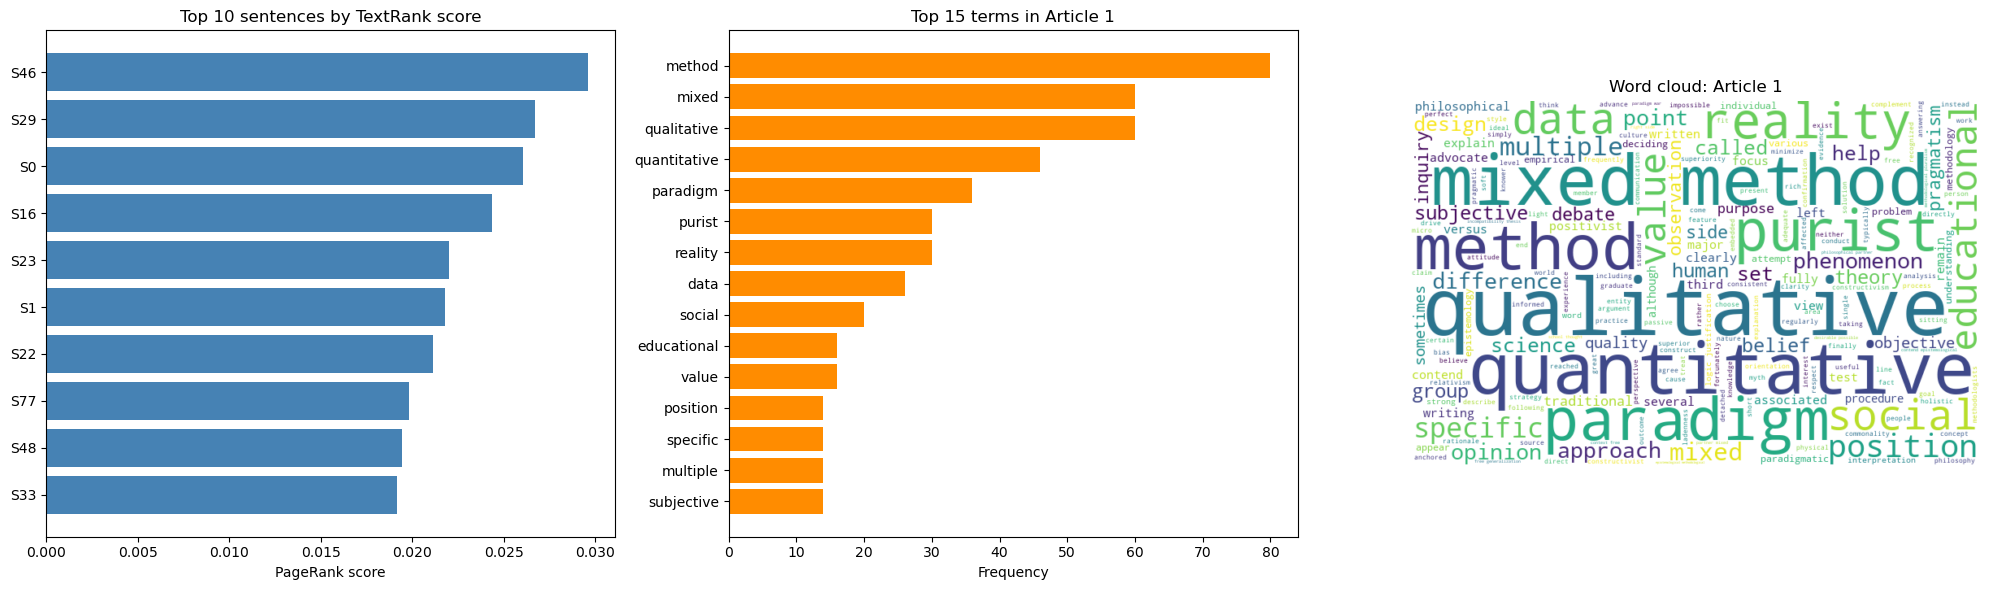

In [6]:
#Q3.3.)

import networkx as nx
from collections import Counter
from nltk.tokenize import sent_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from wordcloud import WordCloud

art1 = articles.iloc[0]

# 1. split into sentences (dict.fromkeys also drops sentences that appear twice in the file)
sentences = list(dict.fromkeys(
    s.strip() for s in sent_tokenize(art1["denoised"]) if len(s.split()) >= 8))
sent_clean = [" ".join(tokenize(s)) for s in sentences]
keep = [i for i, s in enumerate(sent_clean) if s]
sentences  = [sentences[i]  for i in keep]
sent_clean = [sent_clean[i] for i in keep]

# 2. sentence similarity graph
S = TfidfVectorizer().fit_transform(sent_clean)
sim = cosine_similarity(S)
np.fill_diagonal(sim, 0)
G = nx.from_numpy_array(sim)

# 3. PageRank scores each sentence by how central it is
scores = nx.pagerank(G, weight="weight")

# 4. take the top 5 sentences, shown in their original order
TOP_N = 5
top_idx = sorted(sorted(scores, key=scores.get, reverse=True)[:TOP_N])

print("SUMMARY OF ARTICLE 1\n")
for k, i in enumerate(top_idx, 1):
    print(f"{k}. {sentences[i]}\n")
summary_words = sum(len(sentences[i].split()) for i in top_idx)
print(f"Summary is {summary_words / art1['n_words']:.1%} of the original length")

# 5. visualisations
fig, ax = plt.subplots(1, 3, figsize=(20, 6))

rank = sorted(scores.items(), key=lambda x: x[1], reverse=True)[:10]
ax[0].barh([f"S{i}" for i, _ in rank][::-1], [v for _, v in rank][::-1], color="steelblue")
ax[0].set_title("Top 10 sentences by TextRank score"); ax[0].set_xlabel("PageRank score")

freq = Counter(art1["tokens"]).most_common(15)
ax[1].barh([w for w, _ in freq][::-1], [c for _, c in freq][::-1], color="darkorange")
ax[1].set_title("Top 15 terms in Article 1"); ax[1].set_xlabel("Frequency")

wc = WordCloud(width=700, height=450, background_color="white",
               colormap="viridis").generate(art1["clean_text"])
ax[2].imshow(wc, interpolation="bilinear"); ax[2].axis("off"); ax[2].set_title("Word cloud: Article 1")
plt.tight_layout(); plt.show()

Top 15 aggregate terms:
 design           0.035
development      0.030
participant      0.028
reflexivity      0.028
personal         0.027
bias             0.026
student          0.026
reliability      0.025
triangulation    0.025
theory           0.023
interview        0.023
instrument       0.023
education        0.023
developmental    0.022
validity         0.022
dtype: float64
research_2 -> ['reflexivity', 'woman', 'immigrant', 'immigration', 'participant', 'personal', 'reflexivity qualitative', 'researched']
research_3 -> ['developmental', 'instructional', 'development', 'design development', 'design', 'system', 'development process', 'instructional design']
research_4 -> ['alpha', 'cronbach', 'cronbach alpha', 'scale', 'item', 'science education', 'statistic', 'test']
research_5 -> ['denzin', 'triangulation', 'mixed', 'fusch', 'mixed method', 'data triangulation', 'social change', 'methodological triangulation']


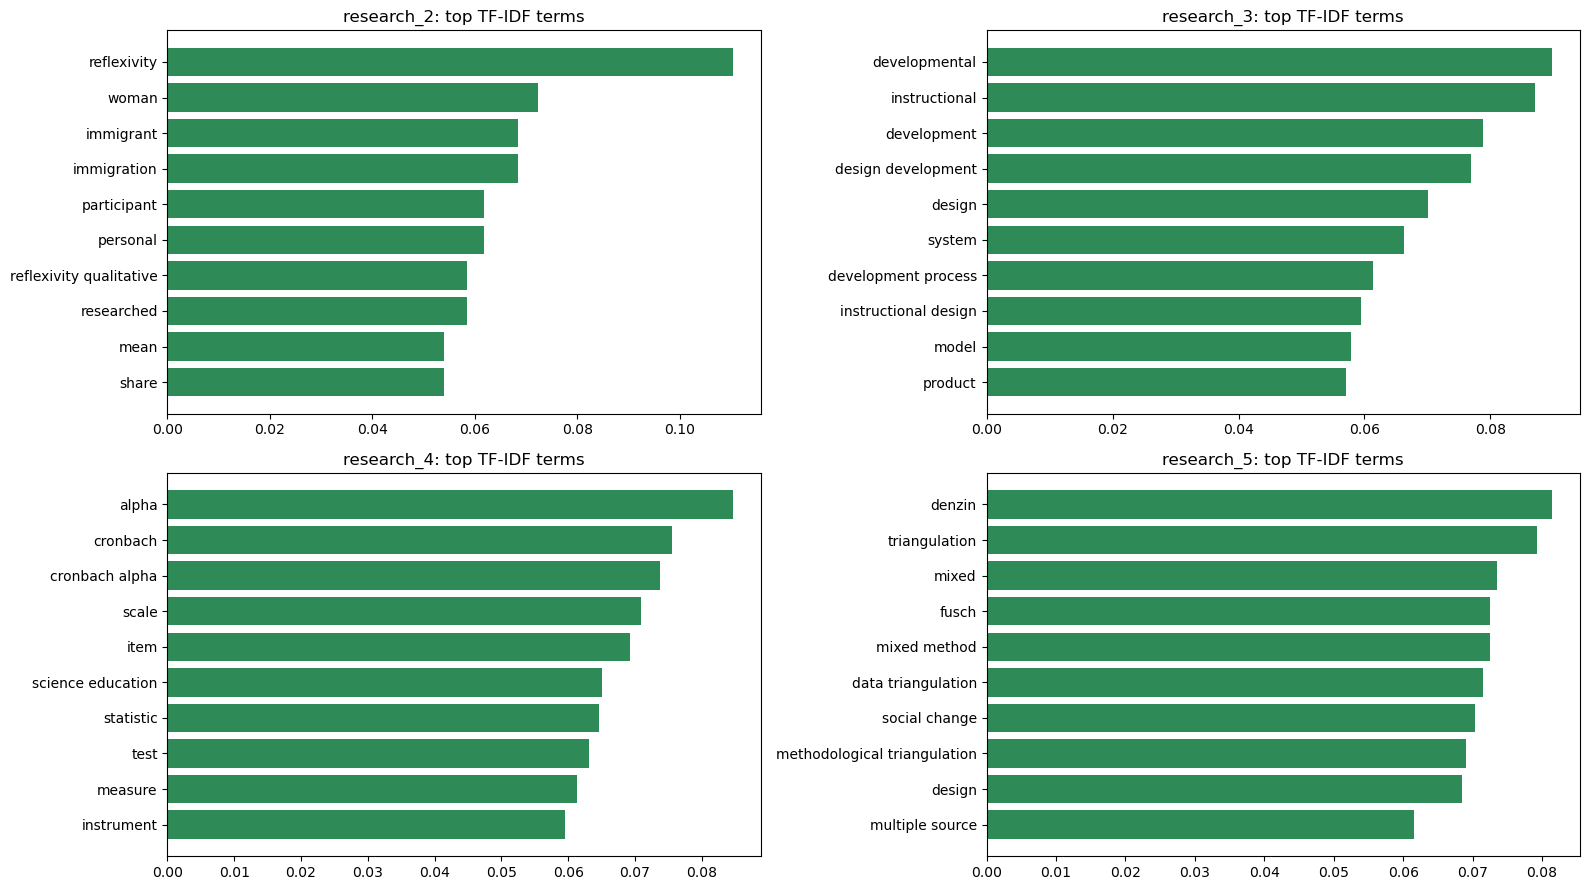

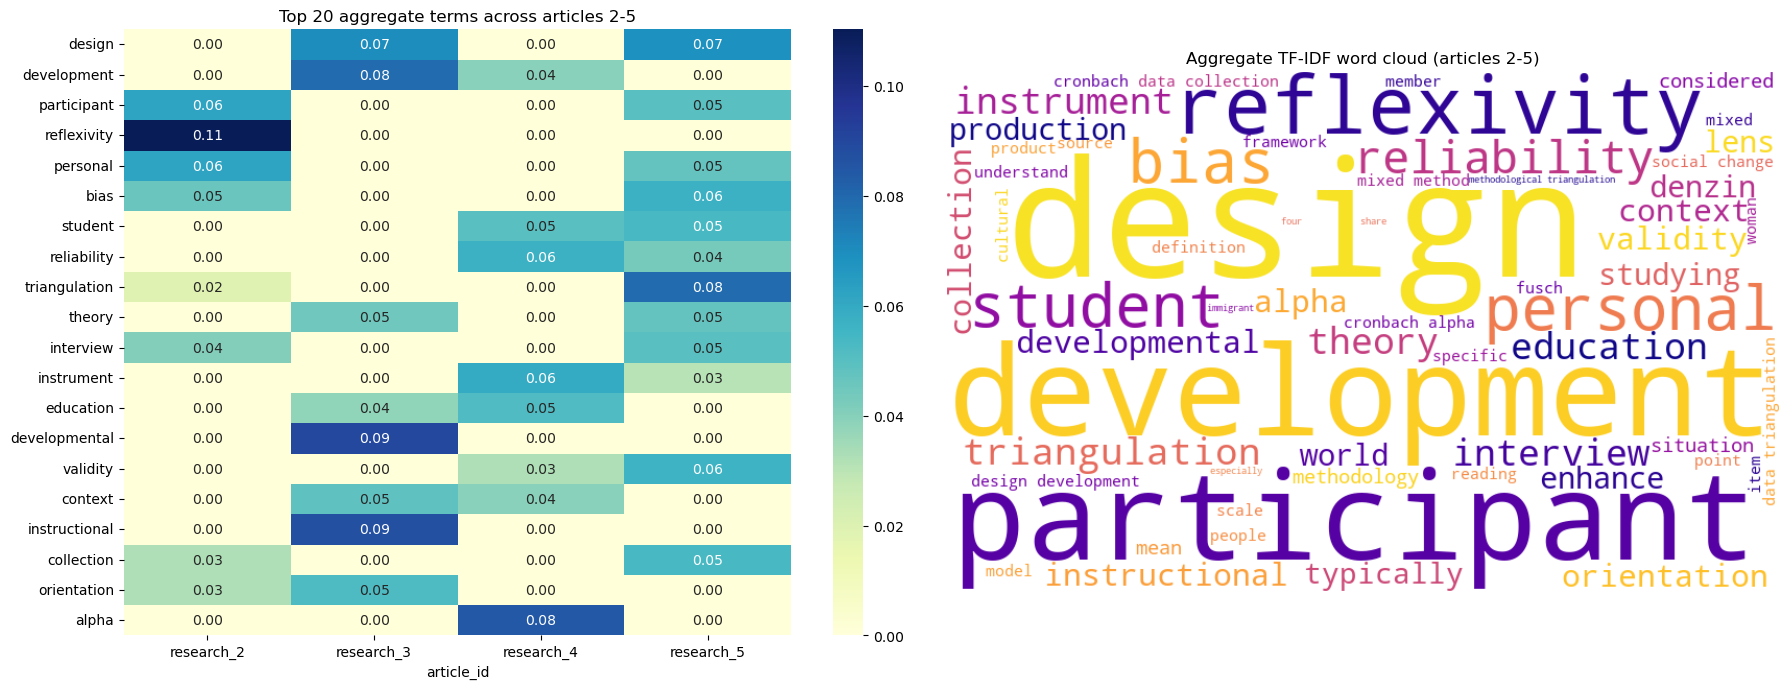

In [7]:
#Q3.4.)

rest = articles.iloc[1:].reset_index(drop=True)

tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_df=0.5, sublinear_tf=True)
M = tfidf.fit_transform(rest["clean_text"])
terms = np.array(tfidf.get_feature_names_out())
M_df = pd.DataFrame(M.toarray(), index=rest["article_id"], columns=terms)

# aggregate importance of each term across the four articles
agg = M_df.mean(axis=0).sort_values(ascending=False)
print("Top 15 aggregate terms:\n", agg.head(15).round(3))
for aid in M_df.index:
    print(aid, "->", list(M_df.loc[aid].nlargest(8).index))

# Chart 1: top terms per article
fig, axes = plt.subplots(2, 2, figsize=(16, 9))
for ax, aid in zip(axes.ravel(), M_df.index):
    s = M_df.loc[aid].nlargest(10)[::-1]
    ax.barh(s.index, s.values, color="seagreen"); ax.set_title(f"{aid}: top TF-IDF terms")
plt.tight_layout(); plt.show()

# Chart 2: heatmap + word cloud of the aggregate
top_terms = agg.head(20).index
fig, ax = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(M_df[top_terms].T, annot=True, fmt=".2f", cmap="YlGnBu", ax=ax[0])
ax[0].set_title("Top 20 aggregate terms across articles 2-5")
wc2 = WordCloud(width=800, height=500, background_color="white",
                colormap="plasma").generate_from_frequencies(agg.head(60).to_dict())
ax[1].imshow(wc2, interpolation="bilinear"); ax[1].axis("off")
ax[1].set_title("Aggregate TF-IDF word cloud (articles 2-5)")
plt.tight_layout(); plt.show()


In [10]:
#Question 4:

#4.1.)

import logging
logging.getLogger("gensim").setLevel(logging.ERROR)
from gensim import corpora
from gensim.models import LdaModel, CoherenceModel

CHUNK = 150
rows = []
for _, r in articles.iterrows():
    words = r["denoised"].split()
    for j in range(0, len(words), CHUNK):
        piece = words[j:j + CHUNK]
        if len(piece) >= 50:                                   # skip tiny trailing fragments
            rows.append({"article_id": r["article_id"], "tokens": tokenize(" ".join(piece))})
chunks = pd.DataFrame(rows)
print("Passages:", len(chunks)); print(chunks.groupby("article_id").size())

texts = chunks["tokens"].tolist()
dictionary = corpora.Dictionary(texts)
dictionary.filter_extremes(no_below=3, no_above=0.4)           # drop very rare and very common words
corpus = [dictionary.doc2bow(t) for t in texts]
print("Vocabulary size:", len(dictionary))

Passages: 140
article_id
research_1    36
research_2    15
research_3    25
research_4    39
research_5    25
dtype: int64
Vocabulary size: 806


2 0.494
3 0.518
4 0.557
5 0.471
6 0.499
7 0.474
8 0.5


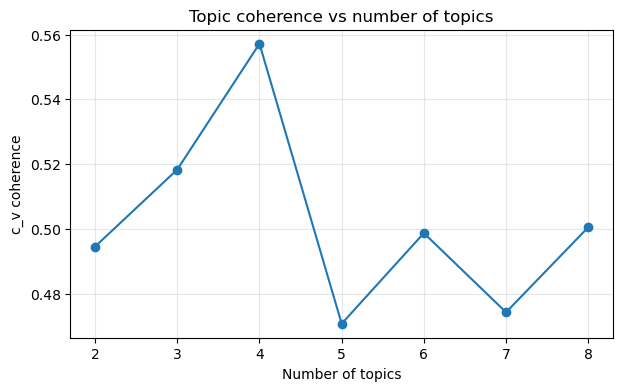

In [12]:
ks, mean_coh = list(range(2, 9)), []
for k in ks:
    sc = []
    for seed in [1, 7, 42]:                                    # average over seeds: LDA is random
        m = LdaModel(corpus, id2word=dictionary, num_topics=k, passes=30,
                     iterations=200, random_state=seed, alpha="auto", eta="auto")
        sc.append(CoherenceModel(model=m, texts=texts, dictionary=dictionary,
                                 coherence="c_v").get_coherence())
    mean_coh.append(np.mean(sc))
    print(k, round(np.mean(sc), 3))

plt.figure(figsize=(7, 4))
plt.plot(ks, mean_coh, "o-"); plt.xlabel("Number of topics"); plt.ylabel("c_v coherence")
plt.title("Topic coherence vs number of topics"); plt.grid(alpha=0.3); plt.show()

In [14]:
N_TOPICS = 4
lda = LdaModel(corpus, id2word=dictionary, num_topics=N_TOPICS, passes=30,
               iterations=200, random_state=7, alpha="auto", eta="auto")

print("Coherence:", round(CoherenceModel(model=lda, texts=texts, dictionary=dictionary,
                                         coherence="c_v").get_coherence(), 3))

topic_table = pd.DataFrame([
    {"Topic": t, "Top words (probability)": ", ".join(f"{w} ({float(p):.3f})"
                                                      for w, p in lda.show_topic(t, 10))}
    for t in range(N_TOPICS)])
pd.set_option("display.max_colwidth", None)
topic_table

Coherence: 0.576


,Topic,Top words (probability)
0,0,"alpha (0.046), instrument (0.026), value (0.025), cronbach (0.024), science (0.020), reliability (0.020), scale (0.018), item (0.017), education (0.013), author (0.012)"
1,1,"data (0.059), triangulation (0.055), denzin (0.019), method (0.019), multiple (0.016), source (0.014), social (0.014), methodological (0.013), qualitative (0.013), point (0.012)"
2,2,"method (0.047), qualitative (0.034), mixed (0.034), design (0.020), quantitative (0.017), paradigm (0.016), reflexivity (0.015), position (0.011), data (0.011), reality (0.011)"
3,3,"development (0.038), process (0.026), developmental (0.022), design (0.021), instructional (0.019), evaluation (0.014), qualitative (0.011), purist (0.010), knowledge (0.010), model (0.010)"


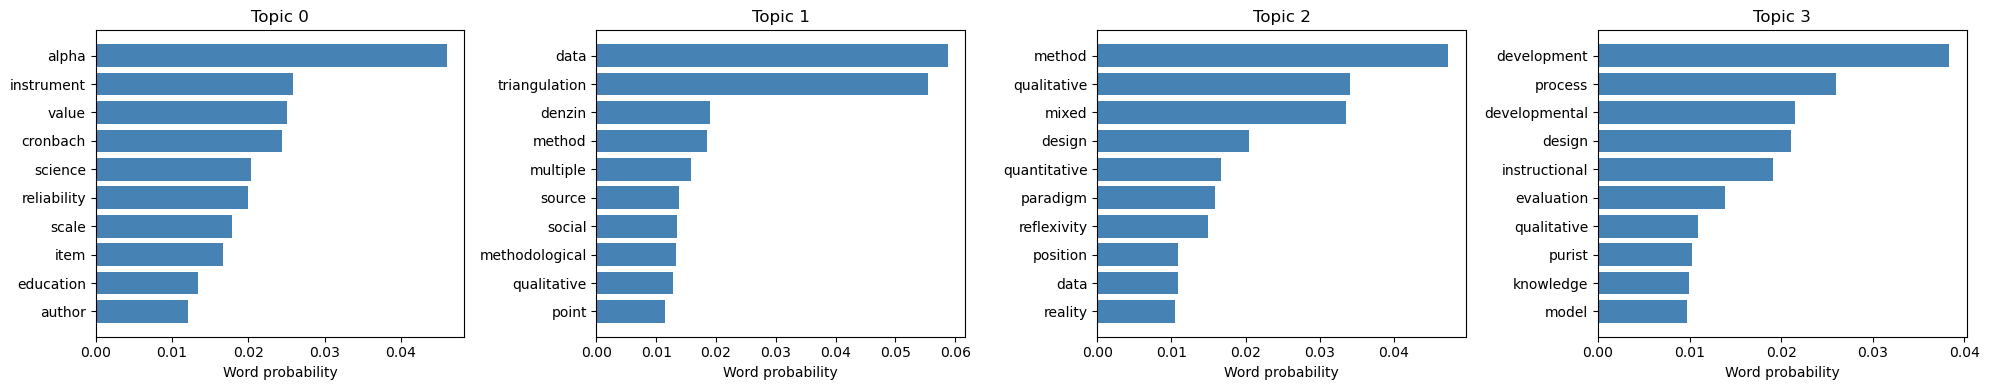

            Topic 0  Topic 1  Topic 2  Topic 3
research_1     0.05     0.17     0.48     0.30
research_2     0.03     0.26     0.61     0.11
research_3     0.07     0.01     0.01     0.91
research_4     0.98     0.01     0.00     0.00
research_5     0.04     0.55     0.41     0.00


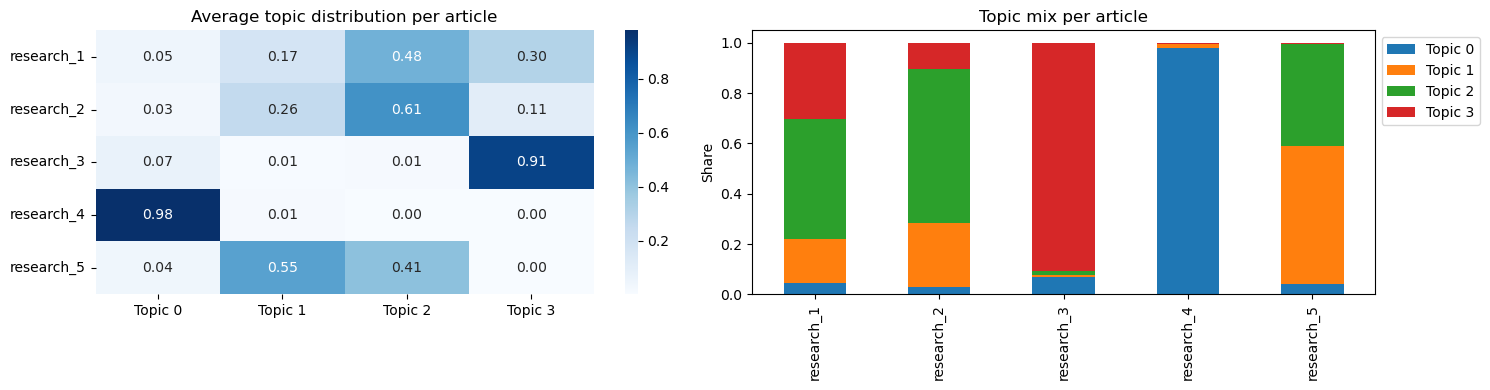

0    0.29
1    0.17
2    0.28
3    0.26
Name: proportion, dtype: float64


In [16]:
# Chart 1: word distribution for each topic
fig, axes = plt.subplots(1, N_TOPICS, figsize=(5 * N_TOPICS, 4))
for t, a in enumerate(axes):
    w = lda.show_topic(t, 10)[::-1]
    a.barh([x for x, _ in w], [float(p) for _, p in w], color="steelblue")
    a.set_title(f"Topic {t}"); a.set_xlabel("Word probability")
plt.tight_layout(); plt.show()

# Topic mix of every passage, then averaged per article
dt = np.zeros((len(corpus), N_TOPICS))
for i, bow in enumerate(corpus):
    for t, p in lda.get_document_topics(bow, minimum_probability=0):
        dt[i, t] = p
art_topic = (pd.DataFrame(dt, columns=[f"Topic {i}" for i in range(N_TOPICS)])
               .groupby(chunks["article_id"].values).mean())
print(art_topic.round(2))

# Chart 2: article-topic heatmap and stacked bars
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
sns.heatmap(art_topic, annot=True, fmt=".2f", cmap="Blues", ax=ax[0])
ax[0].set_title("Average topic distribution per article")
art_topic.plot(kind="bar", stacked=True, ax=ax[1])
ax[1].set_title("Topic mix per article"); ax[1].set_ylabel("Share"); ax[1].legend(bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

# Share of passages whose dominant topic is each topic
print(pd.Series(dt.argmax(axis=1)).value_counts(normalize=True).sort_index().round(2))

In [18]:
#Q4.2.)

import pyLDAvis
import pyLDAvis.gensim_models

pyLDAvis.enable_notebook()
vis = pyLDAvis.gensim_models.prepare(lda, corpus, dictionary, mds="mmds", sort_topics=False)
pyLDAvis.save_html(vis, "lda_visualisation.html")   # standalone file for your repository
vis

PreparedData(topic_coordinates=              x         y  topics  cluster       Freq
topic                                                
0      0.220622  0.102997       1        1  31.688110
1      0.044941 -0.158009       2        1  17.434595
2     -0.159249 -0.097394       3        1  25.263882
3     -0.106313  0.152407       4        1  25.613413, topic_info=              Term        Freq       Total Category  logprob  loglift
316          alpha  108.000000  108.000000  Default  30.0000  30.0000
401  triangulation   75.000000   75.000000  Default  29.0000  29.0000
100           data  109.000000  109.000000  Default  28.0000  28.0000
322    development   84.000000   84.000000  Default  27.0000  27.0000
17          method  123.000000  123.000000  Default  26.0000  26.0000
..             ...         ...         ...      ...      ...      ...
33     qualitative   20.723921  103.734086   Topic4  -4.5172  -0.2485
54         concept    9.759095   33.257226   Topic4  -5.2703   0.1360
87          social   10.128597   44.899673   Topic4  -5.2332  -0.1270
100           data   11.177159  109.849210   Topic4  -5.1347  -0.9232
17          method   10.763221  123.523808   Topic4  -5.1724  -1.0782

[254 rows x 6 columns], token_table=      Topic      Freq        Term
term                             
583       1  0.343230     ability
583       2  0.514846     ability
583       3  0.171615     ability
694       1  0.981284  acceptable
787       2  0.936155         add
...     ...       ...         ...
744       1  0.946346      volume
43        3  0.884736         war
188       3  0.884793    weakness
160       2  0.256336       world
160       3  0.683562       world

[379 rows x 3 columns], R=30, lambda_step=0.01, plot_opts={'xlab': 'PC1', 'ylab': 'PC2'}, topic_order=[1, 2, 3, 4])